# Phase 5 — the frozen blind test: results and error analysis

The final comparison ran once, on blind test splits, from the freeze commit `cff0d20`
(`PREREGISTRATION.md` Phase 5; `reports/phase_5.md`). This notebook reads only stored
artifacts: no model is called, and nothing is rerun.

- **Part A visualizes preregistered outputs** already stored in `analysis.json`. The
  visual forms themselves were created post hoc.
- **Part B derives new descriptive diagnostics** from the frozen records. They describe
  where the systems fail; they are not confirmatory and support no new claims.

**Systems** (the same colour throughout):

- BM25 RAG (top 10) and D3 RAG (R, top 10);
- the matched-context control (D3, top 16);
- the single agent and the multi-agent system;
- two reference systems: the oracle (gold paragraphs only) and closed-book (no context).

**Splits:** `test_agents` (100 questions, 50 bridge + 50 comparison, overall figures
prevalence-weighted 0.799 / 0.201), `test_rag` (200, proportional) and `test_retrieval`
(1,000, proportional).

In [1]:
import collections
import hashlib
import json
import os

import datasets
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

import data
import final
import manifest
import metrics
import scoring

datasets.logging.set_verbosity_error()  # the cached-dataset notice is not a result

# --- chart style: documented validated palette (adjacent-pair order), recessive chrome
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SYSTEMS = ["bm25_k10", "d3_k10", "d3_k16", "agent_single", "multi_agent", "oracle", "closed_book"]
NAME = {"bm25_k10": "BM25 RAG", "d3_k10": "D3 RAG (R)", "d3_k16": "Matched control (K=16)",
        "agent_single": "Single agent", "multi_agent": "Multi-agent", "oracle": "Oracle (reference)",
        "closed_book": "Closed-book (reference)"}
COLOR = dict(zip(SYSTEMS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
MARKER = dict(zip(SYSTEMS, ["o", "s", "D", "^", "v", "P", "X"]))
EXACT, PARTIAL = "#1c5cab", "#86b6ef"                    # blue ramp: answer quality
WRONG = ["#52514e", "#898781", "#c3c2b7"]                # neutral greys: failure locations
WIN, LOSS, TIE = "#2a78d6", "#e34948", "#e1e0d9"         # diverging pair, gray midpoint
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "font.size": 9.5, "legend.frameon": False})


def sha(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()


D = final.out_dir(False)
A = json.load(open(os.path.join(D, "analysis.json")))
AUDIT = json.load(open(os.path.join(D, "audit", "analysis.json")))
QS = {st: data.load_split(final.STAGES[st], unblind=True) for st in final.ORDER}   # unblinded at the freeze
Q = {q.qid: q for q in QS["agents"]}
TYPES = {q: x.type for q, x in Q.items()}
REC = {n: {r["qid"]: r for r in final._load(final.result_path("agents", n, False))} for n in SYSTEMS}
SC = {n: {q: scoring.score(Q[q], r, evidence=n != "closed_book") for q, r in rr.items()} for n, rr in REC.items()}
CORPUS, IDS = data.corpus(), data.doc_id_of()
KEY = lambda d: (CORPUS[d].title, CORPUS[d].text_hash)
print(f"test_agents: {len(Q)} questions {dict(collections.Counter(TYPES.values()))}; systems loaded: {len(REC)}")

test_agents: 100 questions {'bridge': 50, 'comparison': 50}; systems loaded: 7


## Part 0 · Artifact integrity

The runner's frozen consumer check refuses to run on any commit after the freeze, and this
notebook is written later. This is therefore an **artifact-integrity check**, not that
consumer check. It does not weaken or modify the runner's freeze checks.

In order, it checks:

1. **Pinned hashes:** the freeze record, the three stage markers, the audit manifest,
   `labels.csv`, `analysis.json` and the audit result each match a hash pinned here.
2. **Frozen code:** the imported evaluation code and the runner match the hashes in
   `freeze.json`, and the freeze record matches the declaration in `PREREGISTRATION.md`.
   This check comes first so that the runner's own validators can be trusted.
3. **Every stage:** its marker names the freeze commit and the expected system set, every
   result and manifest file matches the marker, and every record passes validation. That
   is 26 result files plus the 2 analysis files, 28 in all.
4. **The audit:** the sheet and key match `audit_manifest.json` and reproduce the frozen
   96-item sample. The labels are validated, and the audit summary recomputed from them
   equals the stored audit result.

In [2]:
PINNED = {
    "freeze.json": "e6c180f8bf86bdf336b23f5855535835044ba3668c8eae08d84016f18198f35c",
    "retrieval.done.json": "06a153e32248358db1bd9826d9ba428b1be445b3d237530fbc92f8e3730218a3",
    "rag.done.json": "568a116f2afe3a79acfefecbdacb8aefacac1353e822619723dcfa8ebd95bc74",
    "agents.done.json": "ea9582e7c2eff05f8bfeeaafb5bf6a0470e2e9af5bfbd64c4920fe07d786c5f1",
    "audit/audit_manifest.json": "dc11fd46e2098444b4b092d262cf37020a5246bc7764bacc2676e2661301d66a",
    "audit/labels.csv": "542e6395c1847634acca32e117a1d46550a0cbb5d48cdd25c29a9629f40e9459",
    "analysis.json": "99f81c00df814b08f7b9bf9ea4c09b923d4aedaf83953ae6c68015ce2a69320f",
    "audit/analysis.json": "0780bf5be6246b4b7c3046aef580722168062cf5eb626574378d927b8211c8a5",
}
bad = [rel for rel, h in PINNED.items() if sha(os.path.join(D, rel)) != h]
FR = final.read_freeze(False)  # describe hashes, and the declaration in PREREGISTRATION.md
if manifest.eval_code_hash() != FR["eval_code_hash"]:
    bad.append("imported evaluation code differs from freeze.json")
if final.runner_source_hash() != FR["runner_source_hash"]:
    bad.append("imported runner differs from freeze.json")
if bad:
    raise SystemExit(f"artifact integrity failed: {bad}")
FREEZE = FR["commit"]
n_files = 0
for st in final.ORDER:
    final.validate_stage(st, False)  # marker vs freeze, system set, file hashes, every record
    with open(final.marker_path(st, False)) as f:
        mk = json.load(f)
    if mk["commit"] != FREEZE or set(mk["systems"]) != set(final.STAGE_SYSTEMS[st]):
        raise SystemExit(f"stage {st}: unexpected marker")
    n_files += 2 * len(mk["systems"])
n_files += 2  # analysis.json and audit/analysis.json, pinned above
if n_files != 28:
    raise SystemExit(f"expected 28 result and analysis files, found {n_files}")
AUD_DIR = os.path.join(D, "audit")
AKEY = final.verify_audit_files(AUD_DIR, Q, {s: REC[s] for s in final.AUDIT_SYSTEMS})
ALAB = final.read_labels(os.path.join(AUD_DIR, "labels.csv"), len(AKEY))
if json.loads(json.dumps(final.audit_summary(AKEY, ALAB))) != AUDIT:
    raise SystemExit("the audit summary recomputed from the labels differs from the stored audit result")
print(f"pinned hashes: {len(PINNED)} files match; evaluation code and runner match freeze.json (commit {FREEZE[:7]})")
print(f"stages: {', '.join(final.ORDER)} validated; {n_files} result and analysis files; systems as frozen")
print(f"audit: sheet and key match the manifest ({len(AKEY)} items); labels validated; recomputed summary equals the stored result")

pinned hashes: 8 files match; evaluation code and runner match freeze.json (commit cff0d20)
stages: retrieval, rag, agents validated; 28 result and analysis files; systems as frozen
audit: sheet and key match the manifest (96 items); labels validated; recomputed summary equals the stored result


## Part A · Preregistered results (values from `analysis.json`)

### Figure 1 · The confirmatory family

**What it plots.**

- **The family:** answer F1 on `test_agents`, three adjacent comparisons.
- **The overall estimate** weights bridge and comparison by validation prevalence.
- **The bootstrap** resamples within type, with Holm correction across the family.
- **Markers:** bridge and comparison deltas (n = 50 each) are shown beside the overall
  estimate, for reading only; they are not tested.

**How to read it.**

- **The shaded band** is a practical-effect reference band (±0.03, the preregistered
  minimum meaningful difference). It is **not an equivalence margin**: none of the tests
  established equivalence.
- **The intervals** are ordinary 95% bootstrap intervals, not adjusted for multiplicity.

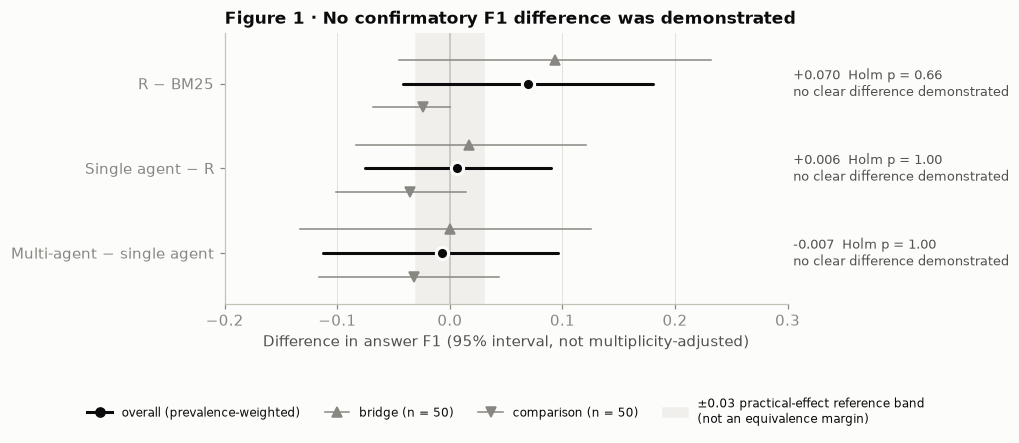

R − BM25: +0.070 [-0.041, +0.181], p 0.221, Holm 0.663 -> no clear difference demonstrated
Single agent − R: +0.006 [-0.075, +0.090], p 0.883, Holm 1.000 -> no clear difference demonstrated
Multi-agent − single agent: -0.007 [-0.113, +0.096], p 0.910, Holm 1.000 -> no clear difference demonstrated


In [3]:
CONF = A["confirmatory"]
LABEL = {"F1": "R − BM25", "F2": "Single agent − R", "F3": "Multi-agent − single agent"}
fig, ax = plt.subplots(figsize=(8.6, 3.2))
ax.axvspan(-final.MPI, final.MPI, color="#f0efec", zorder=0)
ax.axvline(0, color=AXIS, lw=1, zorder=1)
for i, k in enumerate(["F1", "F2", "F3"]):
    y = 2 - i
    v = CONF[k]
    ax.plot([v["ci_low"], v["ci_high"]], [y, y], color=INK, lw=2, solid_capstyle="round", zorder=3)
    ax.plot(v["delta"], y, "o", ms=8, color=INK, mec=SURFACE, mew=2, zorder=4)
    for dy, t, m in ((0.28, "bridge", "^"), (-0.28, "comparison", "v")):
        pt = v["per_type"][t]
        ax.plot([pt["ci_low"], pt["ci_high"]], [y + dy, y + dy], color=MUTED, lw=1, zorder=2)
        ax.plot(pt["delta"], y + dy, m, ms=6, color=MUTED, zorder=2)
    ax.text(0.305, y, f"{v['delta']:+.3f}  Holm p = {v['p_holm']:.2f}\n{v['conclusion']}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks([2, 1, 0], [LABEL[k] for k in ("F1", "F2", "F3")])
ax.set_xlim(-0.2, 0.3)
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("Difference in answer F1 (95% interval, not multiplicity-adjusted)")
ax.set_title("Figure 1 · No confirmatory F1 difference was demonstrated")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], marker="o", color=INK, lw=2, label="overall (prevalence-weighted)"),
                   Line2D([], [], marker="^", color=MUTED, lw=1, label="bridge (n = 50)"),
                   Line2D([], [], marker="v", color=MUTED, lw=1, label="comparison (n = 50)"),
                   plt.Rectangle((0, 0), 1, 1, color="#f0efec", label="±0.03 practical-effect reference band\n(not an equivalence margin)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=4, fontsize=8)
plt.subplots_adjust(right=0.72)
plt.show()
for k in ("F1", "F2", "F3"):
    v = CONF[k]
    print(f"{LABEL[k]}: {v['delta']:+.3f} [{v['ci_low']:+.3f}, {v['ci_high']:+.3f}], p {v['p_value']:.3f}, Holm {v['p_holm']:.3f} -> {v['conclusion']}")

### Figure 2 · Answer F1 by system

- **The large dot** is the prevalence-weighted overall F1; the small markers are bridge and
  comparison (n = 50 each).
- **The oracle and closed-book are reference systems.**
  - The oracle reads only the two gold paragraphs. It is a gold-context reader reference,
    not a guaranteed ceiling.
  - Closed-book answers with no context at all.

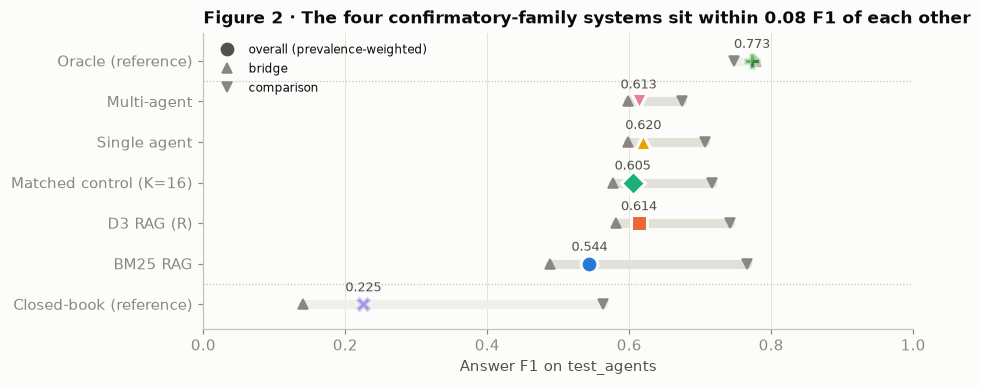

weighted F1: Closed-book (reference) 0.225, BM25 RAG 0.544, Matched control (K=16) 0.605, Multi-agent 0.613, D3 RAG (R) 0.614, Single agent 0.620, Oracle (reference) 0.773
spread of the four confirmatory-family systems: 0.076; bridge-comparison gap for BM25: +0.279


In [4]:
SYS_A = A["test_agents"]["systems"]
four = {n: SYS_A[n]["f1"]["overall"] for n in ("bm25_k10", "d3_k10", "agent_single", "multi_agent")}
spread = max(four.values()) - min(four.values())
order = ["closed_book", "bm25_k10", "d3_k10", "d3_k16", "agent_single", "multi_agent", "oracle"]
fig, ax = plt.subplots(figsize=(8.6, 3.6))
for y, n in enumerate(order):
    f = SYS_A[n]["f1"]
    ref = n in ("oracle", "closed_book")
    ax.plot([f["bridge"], f["comparison"]], [y, y], color=GRID if not ref else "#f0efec", lw=6, solid_capstyle="round", zorder=1)
    ax.plot(f["bridge"], y, "^", ms=6, color=MUTED, zorder=2)
    ax.plot(f["comparison"], y, "v", ms=6, color=MUTED, zorder=2)
    ax.plot(f["overall"], y, MARKER[n], ms=11, color=COLOR[n], mec=SURFACE, mew=2, zorder=3, alpha=0.55 if ref else 1)
    ax.text(f["overall"], y + 0.32, f"{f['overall']:.3f}", ha="center", fontsize=8.5, color=INK2)
ax.axhline(0.5, color=AXIS, lw=0.8, ls=":")
ax.axhline(5.5, color=AXIS, lw=0.8, ls=":")
ax.set_yticks(range(len(order)), [NAME[n] for n in order])
for lab in ax.get_yticklabels():
    if "reference" in lab.get_text():
        lab.set_color(MUTED)
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(order) - 0.3)
ax.set_xlabel("Answer F1 on test_agents")
ax.grid(axis="y", visible=False)
ax.set_title(f"Figure 2 · The four confirmatory-family systems sit within {spread:.2f} F1 of each other")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=INK2, ms=8, label="overall (prevalence-weighted)"),
                   Line2D([], [], marker="^", ls="", color=MUTED, label="bridge"),
                   Line2D([], [], marker="v", ls="", color=MUTED, label="comparison")], loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
ranked = sorted(order, key=lambda n: SYS_A[n]["f1"]["overall"])
print("weighted F1:", ", ".join(f"{NAME[n]} {SYS_A[n]['f1']['overall']:.3f}" for n in ranked))
print(f"spread of the four confirmatory-family systems: {spread:.3f}; "
      f"bridge-comparison gap for BM25: {SYS_A['bm25_k10']['f1']['comparison'] - SYS_A['bm25_k10']['f1']['bridge']:+.3f}")

### Figures 3 and 4 · Quality against cost, and evidence against quality *(planned plots)*

**Figure 3, the cost axis.**

- **What it measures:** the median, per question, of logical LLM wall-time attributed
  from call records. It is a weighted empirical quantile.
- **What it is not:** a cache hit keeps its original latency, so this is neither physical
  generation time nor session runtime.

**Figure 4, the evidence axis.** Final-context Joint Recall: the share of questions with
both gold paragraphs in the answer context.

**Identity.** Points carry direct labels and distinct markers as well as colour; with
more than three series, colour alone is not reliably distinguishable.

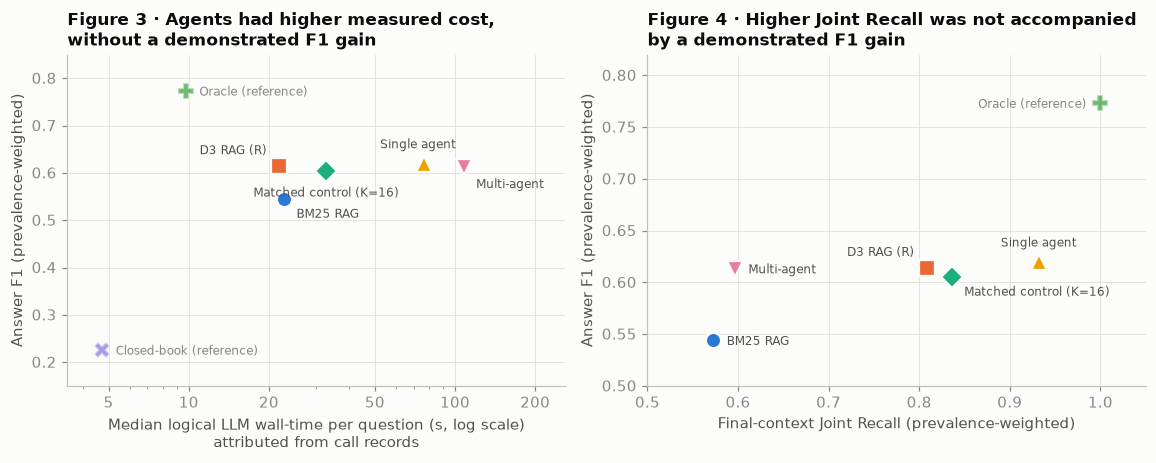

median attributed LLM time per question (s): BM25 RAG 22.9, D3 RAG (R) 21.9, Matched control (K=16) 32.8, Single agent 76.6, Multi-agent 108.0, Oracle (reference) 9.7, Closed-book (reference) 4.7
relative to R: single agent 3.5x, multi-agent 4.9x
Joint Recall: BM25 RAG 0.572, D3 RAG (R) 0.808, Matched control (K=16) 0.836, Single agent 0.932, Multi-agent 0.596, Oracle (reference) 1.000


In [5]:
fig, (a3, a4) = plt.subplots(1, 2, figsize=(10.6, 4.3))
ev = [n for n in SYSTEMS if n != "closed_book"]
OFF3 = {"bm25_k10": (8, -12, "left"), "d3_k10": (-8, 8, "right"), "d3_k16": (0, -17, "center"), "agent_single": (-4, 10, "center"),
        "multi_agent": (8, -14, "left"), "oracle": (9, -3, "left"), "closed_book": (9, -3, "left")}
OFF4 = {"bm25_k10": (9, -3, "left"), "d3_k10": (-8, 8, "right"), "d3_k16": (8, -12, "left"), "agent_single": (0, 10, "center"),
        "multi_agent": (9, -3, "left"), "oracle": (-9, -3, "right")}
for n in SYSTEMS:
    ref = n in ("oracle", "closed_book")
    f1 = SYS_A[n]["f1"]["overall"]
    t = SYS_A[n]["cost"]["llm_seconds"]["p50"]
    style = dict(ms=10, color=COLOR[n], mec=SURFACE, mew=1.5, alpha=0.55 if ref else 1, zorder=3)
    a3.plot(t, f1, MARKER[n], **style)
    dx, dy, ha = OFF3[n]
    a3.annotate(NAME[n], (t, f1), xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=ha, color=MUTED if ref else INK2)
    if n in ev:
        jr = SYS_A[n]["ctx_joint_recall"]["overall"]
        a4.plot(jr, f1, MARKER[n], **style)
        dx, dy, ha = OFF4[n]
        a4.annotate(NAME[n], (jr, f1), xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=ha, color=MUTED if ref else INK2)
a3.set_xscale("log")
a3.set_xticks([5, 10, 20, 50, 100, 200], ["5", "10", "20", "50", "100", "200"])
a3.set_xlim(3.5, 260)
a3.set_ylim(0.15, 0.85)
a3.set_xlabel("Median logical LLM wall-time per question (s, log scale)\nattributed from call records")
a3.set_ylabel("Answer F1 (prevalence-weighted)")
a3.set_title("Figure 3 · Agents had higher measured cost,\nwithout a demonstrated F1 gain")
a4.set_xlim(0.5, 1.05)
a4.set_ylim(0.5, 0.82)
a4.set_xlabel("Final-context Joint Recall (prevalence-weighted)")
a4.set_ylabel("Answer F1 (prevalence-weighted)")
a4.set_title("Figure 4 · Higher Joint Recall was not accompanied\nby a demonstrated F1 gain")
plt.tight_layout()
plt.show()
cost = {n: SYS_A[n]["cost"]["llm_seconds"]["p50"] for n in SYSTEMS}
print("median attributed LLM time per question (s):", ", ".join(f"{NAME[n]} {cost[n]:.1f}" for n in SYSTEMS))
print(f"relative to R: single agent {cost['agent_single'] / cost['d3_k10']:.1f}x, multi-agent {cost['multi_agent'] / cost['d3_k10']:.1f}x")
print("Joint Recall:", ", ".join(f"{NAME[n]} {SYS_A[n]['ctx_joint_recall']['overall']:.3f}" for n in ev))

### Figure 5 · Retrieval on `test_retrieval` (n = 1,000; 799 bridge, 201 comparison)

- **Measure:** Joint Recall@K, the share of questions with both gold paragraphs in the top
  K, at the six frozen K values.
- **Lines** only join the measured points; nothing is interpolated between them.
- **The split** is a proportional sample, so the figures are unweighted.

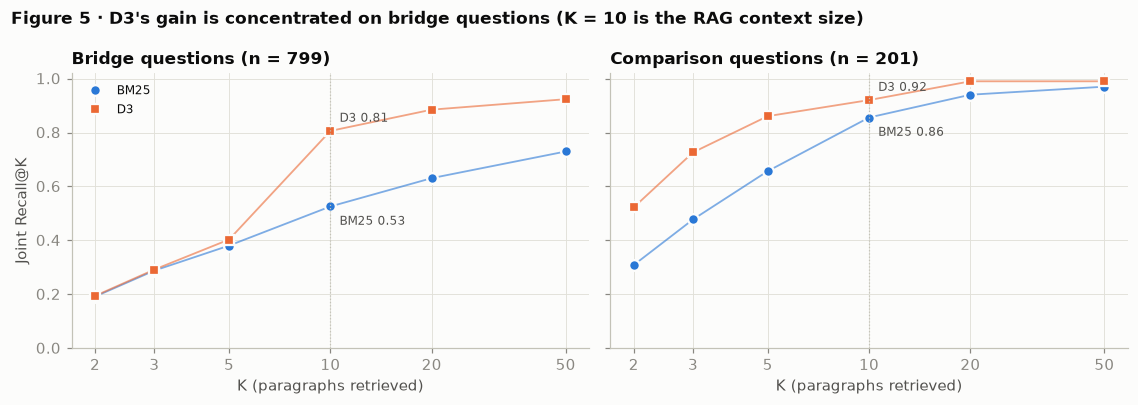

Joint Recall@10: BM25 0.592 -> D3 0.829; D3 - BM25 +0.237 [+0.207, +0.268]
by type at K=10: bridge 0.526 -> 0.806; comparison 0.856 -> 0.920
title-only vs exact-variant Joint Recall: largest difference 0.001 (exact shown)


In [6]:
RET = A["test_retrieval"]
KS = [2, 3, 5, 10, 20, 50]
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7), sharey=True)
for ax, t in zip(axes, ("bridge", "comparison")):
    for n, sysname, key in (("bm25_rankings", "BM25", "bm25_k10"), ("d3_rankings", "D3", "d3_k10")):
        ys = [RET[n]["curves"][f"joint_recall@{k}"][t] for k in KS]
        ax.plot(KS, ys, "-", color=COLOR[key], lw=1.2, alpha=0.6)
        ax.plot(KS, ys, MARKER[key], ms=7, color=COLOR[key], mec=SURFACE, mew=1.5, label=sysname)
        ax.annotate(f"{sysname} {ys[3]:.2f}", (10, ys[3]), xytext=(6, -12 if sysname == "BM25" else 6),
                    textcoords="offset points", fontsize=8, color=INK2)
    ax.axvline(10, color=AXIS, lw=0.8, ls=":")
    ax.set_xscale("log")
    ax.set_xticks(KS, [str(k) for k in KS])
    ax.minorticks_off()
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("K (paragraphs retrieved)")
    ax.set_title(f"{t.capitalize()} questions (n = {sum(1 for q in QS['retrieval'] if q.type == t)})")
axes[0].set_ylabel("Joint Recall@K")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Figure 5 · D3's gain is concentrated on bridge questions (K = 10 is the RAG context size)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()
c = {n: RET[n]["curves"] for n in ("bm25_rankings", "d3_rankings")}
d = RET["jr10_d3_minus_bm25"]
print(f"Joint Recall@10: BM25 {c['bm25_rankings']['joint_recall@10']['overall']:.3f} -> D3 {c['d3_rankings']['joint_recall@10']['overall']:.3f}; "
      f"D3 - BM25 {d['delta']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]")
print("by type at K=10: " + "; ".join(f"{t} {c['bm25_rankings']['joint_recall@10'][t]:.3f} -> {c['d3_rankings']['joint_recall@10'][t]:.3f}"
                                     for t in ("bridge", "comparison")))
gap = max(abs(c[n][f"joint_recall@{k}"]["overall"] - c[n][f"title_joint_recall@{k}"]["overall"]) for n in c for k in KS)
print(f"title-only vs exact-variant Joint Recall: largest difference {gap:.3f} (exact shown)")

### Figure 6 · The evidence funnel (`test_agents`)

- **Measure:** Joint Recall at three stages: after search 1 (which is R's top 10), over the
  whole search pool, and in the final answer context. Values are prevalence-weighted.
- **Raw counts** in the balanced 50 + 50 sample are printed below the figure.
- **The single agent keeps** everything it finds. **The multi-agent system discards
  retrieved evidence** at selection.

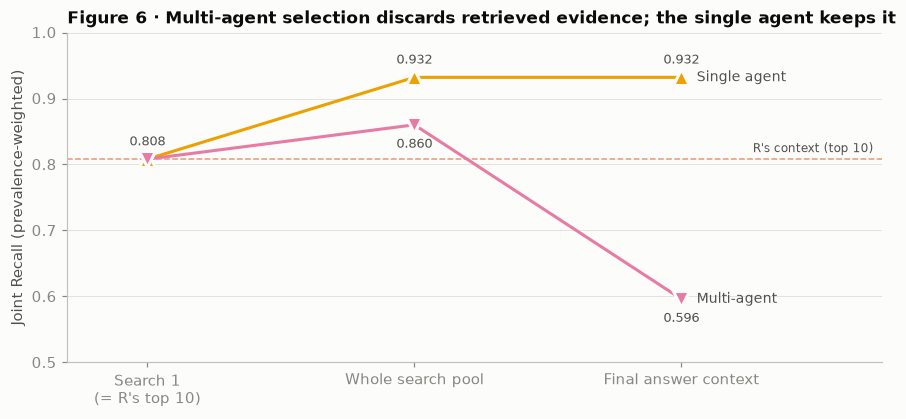

Single agent: 0.808 (85/100 raw) -> 0.932 (95/100 raw) -> 0.932 (95/100 raw)
Multi-agent: 0.808 (85/100 raw) -> 0.860 (89/100 raw) -> 0.596 (65/100 raw)


In [7]:
AG = A["test_agents"]["agents"]
STAGES_F = ["search_1", "search_pool", "final_context"]
STAGE_LABEL = ["Search 1\n(= R's top 10)", "Whole search pool", "Final answer context"]
fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.axhline(SYS_A["d3_k10"]["ctx_joint_recall"]["overall"], color=COLOR["d3_k10"], lw=1, ls="--", alpha=0.7)
ax.text(2.72, SYS_A["d3_k10"]["ctx_joint_recall"]["overall"] + 0.006, "R's context (top 10)", ha="right", va="bottom", fontsize=8, color=INK2)
for n in ("agent_single", "multi_agent"):
    ys = [AG[n]["funnel"][s]["overall"] for s in STAGES_F]
    ax.plot(range(3), ys, "-", color=COLOR[n], lw=2)
    ax.plot(range(3), ys, MARKER[n], ms=10, color=COLOR[n], mec=SURFACE, mew=2)
    for i, y in enumerate(ys):
        if i > 0 or n == "agent_single":
            ax.annotate(f"{y:.3f}", (i, y), xytext=(0, 9 if n == "agent_single" else -15), textcoords="offset points",
                        ha="center", fontsize=8.5, color=INK2)
    ax.annotate(NAME[n], (2, ys[2]), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_xticks(range(3), STAGE_LABEL)
ax.set_xlim(-0.3, 2.75)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Joint Recall (prevalence-weighted)")
ax.grid(axis="x", visible=False)
ax.set_title("Figure 6 · Multi-agent selection discards retrieved evidence; the single agent keeps it")
plt.tight_layout()
plt.show()
raw = lambda n, s: round(AG[n]["funnel"][s]["bridge"] * 50 + AG[n]["funnel"][s]["comparison"] * 50)
for n in ("agent_single", "multi_agent"):
    print(f"{NAME[n]}: " + " -> ".join(f"{AG[n]['funnel'][s]['overall']:.3f} ({raw(n, s)}/100 raw)" for s in STAGES_F))

### Figure 7 · Cost profile (`test_agents`, prevalence-weighted per question)

- **Measures:** logical LLM calls, prompt tokens, and the median logical LLM wall-time
  attributed from call records.
- **Not session runtime:** a cache hit keeps its original latency, so the time panel is
  not session runtime.

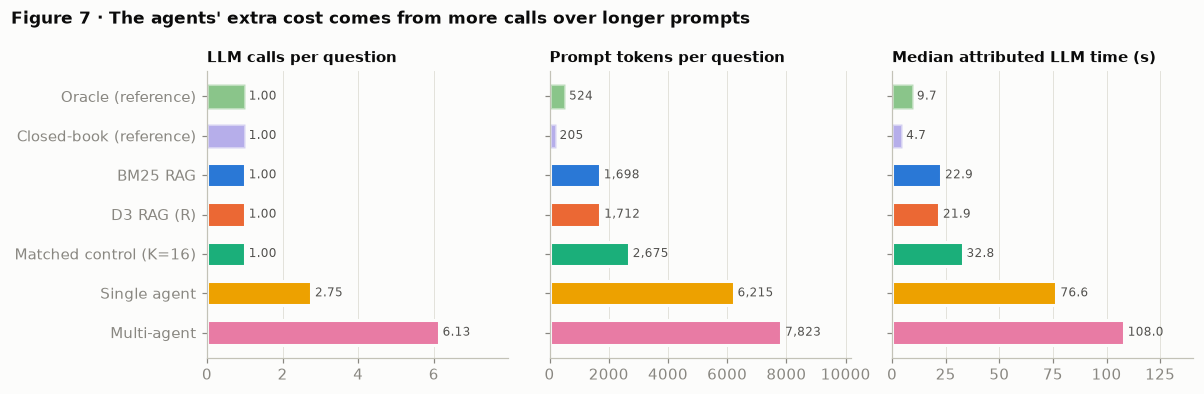

calls/question: D3 RAG (R) 1.00, Single agent 2.75, Multi-agent 6.13
prompt tokens/question: D3 RAG (R) 1,712, Single agent 6,215, Multi-agent 7,823
unique new generations on test_agents: BM25 RAG 84, D3 RAG (R) 84, Matched control (K=16) 100, Single agent 246, Multi-agent 605, Oracle (reference) 84, Closed-book (reference) 84


In [8]:
order7 = ["oracle", "closed_book", "bm25_k10", "d3_k10", "d3_k16", "agent_single", "multi_agent"][::-1]
panels = [("LLM calls per question", lambda c: c["logical_calls"]["per_question"]["overall"], "{:.2f}"),
          ("Prompt tokens per question", lambda c: c["prompt_tokens"]["per_question"]["overall"], "{:,.0f}"),
          ("Median attributed LLM time (s)", lambda c: c["llm_seconds"]["p50"], "{:.1f}")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (title, get, fmt) in zip(axes, panels):
    vals = [get(SYS_A[n]["cost"]) for n in order7]
    for y, (n, v) in enumerate(zip(order7, vals)):
        ref = n in ("oracle", "closed_book")
        ax.barh(y, v, height=0.62, color=COLOR[n], alpha=0.45 if ref else 1, edgecolor=SURFACE, linewidth=2)
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK2)
    ax.set_xlim(0, max(vals) * 1.3)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order7)), [NAME[n] for n in order7])
fig.suptitle("Figure 7 · The agents' extra cost comes from more calls over longer prompts", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()
c = {n: SYS_A[n]["cost"] for n in SYSTEMS}
print("calls/question: " + ", ".join(f"{NAME[n]} {c[n]['logical_calls']['per_question']['overall']:.2f}" for n in ("d3_k10", "agent_single", "multi_agent")))
print("prompt tokens/question: " + ", ".join(f"{NAME[n]} {c[n]['prompt_tokens']['per_question']['overall']:,.0f}" for n in ("d3_k10", "agent_single", "multi_agent")))
print(f"unique new generations on test_agents: " + ", ".join(f"{NAME[n]} {c[n]['unique_new_generations']}" for n in SYSTEMS))

## Part B · Error analysis on `test_agents` *(post hoc, descriptive)*

These diagnostics were derived after the results were inspected. They describe where each
system's answers fall short. They are not confirmatory, and they **associate** an outcome
with a location in the pipeline without establishing what caused it.

**Answer outcome.** The project's existing scorer taxonomy (`scoring.answer_outcome`) is
used; no new threshold is chosen:

- **exact:** EM = 1;
- **partial:** EM = 0 and F1 ≥ 0.5;
- **wrong:** F1 < 0.5.

**Where a wrong answer sits.** The four classes are mutually exclusive, and are defined
on the final context, the stage every system shares:

1. **Exact answer.**
2. **Partial answer.**
3. **Wrong, with incomplete final context.** At least one gold paragraph was not among the
   paragraphs shown to the answer step.
4. **Wrong despite complete gold context.** Both gold paragraphs were shown. This outcome
   is consistent with a reasoning error, an answer-granularity mismatch, an annotation
   problem or a metric mismatch; the records cannot tell these apart.

**What is not compared across systems.** Whether a missing gold paragraph was never
retrieved, or was retrieved and then dropped, depends on each system's search pool. That
pool differs by design: a depth-100 ranking for the RAG systems, at most 20 searched
paragraphs for the agents. That question is analysed only within the multi-agent pipeline
(Figure 11), where it is well defined.

**Systems covered:** BM25, R, the matched control, the single agent and the multi-agent
system. Closed-book has no evidence, so it is excluded.

**Counts** are raw, within the balanced sample (50 bridge + 50 comparison), and shown by
type.

In [9]:
TAX_SYS = ["bm25_k10", "d3_k10", "d3_k16", "agent_single", "multi_agent"]
CLASSES = ["exact", "partial", "wrong · incomplete final context", "wrong · complete gold context"]
CLASS_COLOR = dict(zip(CLASSES, [EXACT, PARTIAL, WRONG[0], WRONG[1]]))


def pool(n, r):  # the search pool; used within the multi-agent pipeline (Figure 11)
    return r["ranked"] if "ranked" in r else [d for b in r["batches"] for d in b]


def has_both(ids, q):
    return set(Q[q].gold) <= {KEY(d) for d in ids}


def classify(n, q):
    s, r = SC[n][q], REC[n][q]
    outcome = scoring.answer_outcome(s["em"], s["f1"])
    if outcome == "correct":
        return "exact"
    if outcome == "partial":
        return "partial"
    return CLASSES[2] if not has_both(r["displayed"], q) else CLASSES[3]


TAX = {n: {q: classify(n, q) for q in Q} for n in TAX_SYS}
COUNTS = {t: {n: collections.Counter(c for q, c in TAX[n].items() if TYPES[q] == t) for n in TAX_SYS} for t in ("bridge", "comparison")}
for t in ("bridge", "comparison"):
    print(t)
    for n in TAX_SYS:
        print(f"  {NAME[n]:24s} " + "  ".join(f"{c.split(' · ')[-1]}: {COUNTS[t][n][c]:2d}" for c in CLASSES))
print("final context size (paragraphs, prevalence-weighted mean):",
      ", ".join(f"{NAME[n]} {SYS_A[n]['final_context_size']['overall']:.1f}" for n in TAX_SYS))

bridge
  BM25 RAG                 exact: 22  partial:  2  incomplete final context: 18  complete gold context:  8
  D3 RAG (R)               exact: 26  partial:  3  incomplete final context:  9  complete gold context: 12
  Matched control (K=16)   exact: 26  partial:  2  incomplete final context:  7  complete gold context: 15
  Single agent             exact: 27  partial:  3  incomplete final context:  2  complete gold context: 18
  Multi-agent              exact: 27  partial:  3  incomplete final context: 14  complete gold context:  6
comparison
  BM25 RAG                 exact: 35  partial:  4  incomplete final context:  1  complete gold context: 10
  D3 RAG (R)               exact: 34  partial:  4  incomplete final context:  1  complete gold context: 11
  Matched control (K=16)   exact: 33  partial:  4  incomplete final context:  0  complete gold context: 13
  Single agent             exact: 33  partial:  3  incomplete final context:  0  complete gold context: 14
  Multi-agent      

### Figure 8 · Answer outcome and the final context

**One caveat on comparability.** All five systems are classified at the same stage, the
final context, but its size differs (printed above): 10 paragraphs for BM25 and R, 16 for
the matched control. The agents' contexts vary per question: the single agent keeps
every searched paragraph, while the multi-agent synthesizer sees only accepted evidence,
far fewer paragraphs on average. A larger context makes complete gold context easier to
reach.

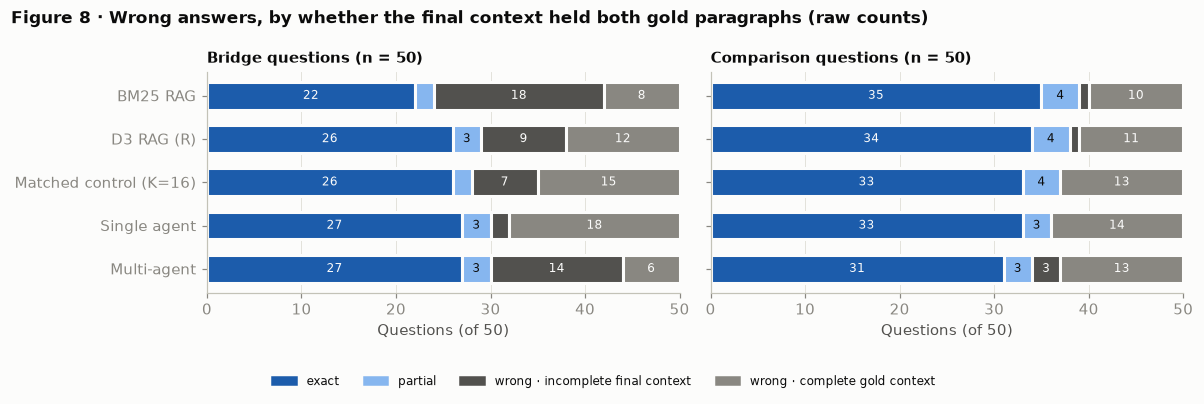

BM25 RAG                 bridge wrong: 26 (incomplete final context 18, complete gold context 8)
D3 RAG (R)               bridge wrong: 21 (incomplete final context 9, complete gold context 12)
Matched control (K=16)   bridge wrong: 22 (incomplete final context 7, complete gold context 15)
Single agent             bridge wrong: 20 (incomplete final context 2, complete gold context 18)
Multi-agent              bridge wrong: 20 (incomplete final context 14, complete gold context 6)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
rows = TAX_SYS[::-1]
for ax, t in zip(axes, ("bridge", "comparison")):
    for y, n in enumerate(rows):
        left = 0
        for c in CLASSES:
            v = COUNTS[t][n][c]
            if v:
                ax.barh(y, v, left=left, height=0.64, color=CLASS_COLOR[c], edgecolor=SURFACE, linewidth=2)
                if v >= 3:
                    ax.text(left + v / 2, y, str(v), ha="center", va="center", fontsize=8,
                            color=SURFACE if c in ("exact", CLASSES[2], CLASSES[3]) else INK)
                left += v
    ax.set_xlim(0, 50)
    ax.set_xlabel("Questions (of 50)")
    ax.set_title(f"{t.capitalize()} questions (n = 50)", fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(rows)), [NAME[n] for n in rows])
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[c], label=c) for c in CLASSES],
           loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Figure 8 · Wrong answers, by whether the final context held both gold paragraphs (raw counts)", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
for n in TAX_SYS:
    b = COUNTS["bridge"][n]
    print(f"{NAME[n]:24s} bridge wrong: {sum(b[c] for c in CLASSES[2:]):2d} "
          f"(incomplete final context {b[CLASSES[2]]}, complete gold context {b[CLASSES[3]]})")

### Figure 9 · Question-by-system outcome map

- **Layout:** each column is one `test_agents` question; each row is a system.
- **Colour:** the cell's answer outcome (exact / partial / wrong).
- **Ordering:** within each type, questions are sorted by how many of the five compared
  systems answered exactly, then by mean F1.
- **How to read the shared low scores:** columns where every system scores low are
  candidates for genuinely hard questions or label problems. The map does not prove
  either.

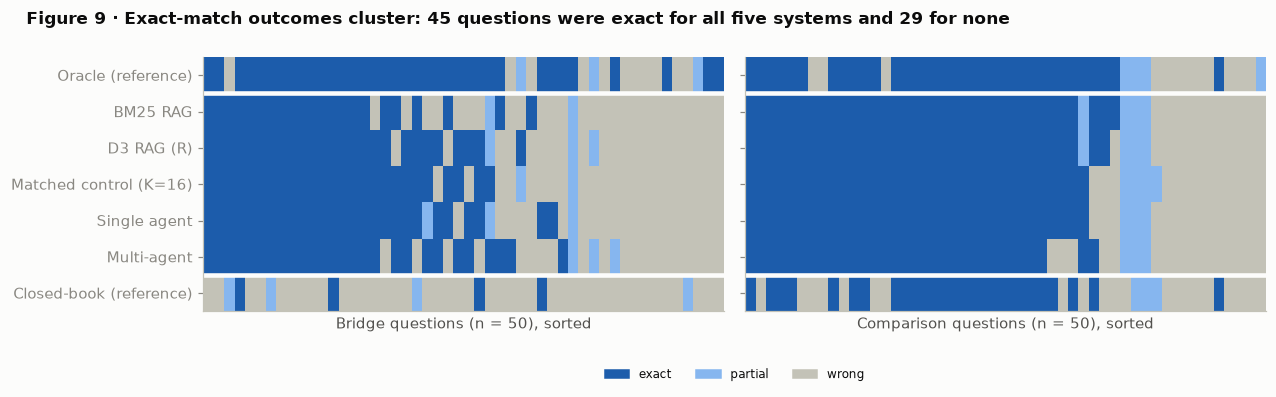

questions by number of the five compared systems answering exactly: {0: 29, 1: 7, 2: 3, 3: 8, 4: 8, 5: 45}
all five compared systems wrong: 22 (12 bridge); of these, the oracle (gold paragraphs only) was also wrong on 16 (candidates for hard questions or label problems, not proof of either)


In [11]:
from matplotlib.colors import ListedColormap
ROWS9 = ["oracle", "bm25_k10", "d3_k10", "d3_k16", "agent_single", "multi_agent", "closed_book"]
STATE = {"correct": 2, "partial": 1, "wrong": 0}
outcome = {n: {q: scoring.answer_outcome(SC[n][q]["em"], SC[n][q]["f1"]) for q in Q} for n in ROWS9}
cmap = ListedColormap(["#c3c2b7", PARTIAL, EXACT])
n_exact = {q: sum(outcome[n][q] == "correct" for n in TAX_SYS) for q in Q}
dist = collections.Counter(n_exact.values())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
fig.subplots_adjust(left=0.15, right=0.99, top=0.86, bottom=0.2, wspace=0.04)
order_by_type = {}
for ax, t in zip(axes, ("bridge", "comparison")):
    qs = [q for q in Q if TYPES[q] == t]
    qs.sort(key=lambda q: (-sum(outcome[n][q] == "correct" for n in TAX_SYS), -np.mean([SC[n][q]["f1"] for n in TAX_SYS]), q))
    order_by_type[t] = qs
    M = np.array([[STATE[outcome[n][q]] for q in qs] for n in ROWS9])
    ax.imshow(M, aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks(range(len(ROWS9)), [NAME[n] for n in ROWS9] if t == "bridge" else [])
    ax.set_xlabel(f"{t.capitalize()} questions (n = 50), sorted")
    ax.grid(False)
    for y in (0.5, 5.5):
        ax.axhline(y, color=SURFACE, lw=3)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=l) for c, l in ((EXACT, "exact"), (PARTIAL, "partial"), ("#c3c2b7", "wrong"))],
           loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.57, -0.01))
fig.suptitle(f"Figure 9 · Exact-match outcomes cluster: {dist[len(TAX_SYS)]} questions were exact for all five systems and {dist[0]} for none", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
plt.show()
all_wrong = [q for q in Q if all(outcome[n][q] == "wrong" for n in TAX_SYS)]
print("questions by number of the five compared systems answering exactly:", dict(sorted(dist.items())))
print(f"all five compared systems wrong: {len(all_wrong)} ({sum(TYPES[q] == 'bridge' for q in all_wrong)} bridge); "
      f"of these, the oracle (gold paragraphs only) was also wrong on {sum(outcome['oracle'][q] == 'wrong' for q in all_wrong)} "
      "(candidates for hard questions or label problems, not proof of either)")

### Figure 10 · Paired per-question F1 against R

- **What each panel shows:** one comparison system against R (D3 RAG, top 10) on the same
  100 questions. Each bar is one question's F1 difference (system − R), sorted from
  largest gain to largest loss.
- **Colour:** blue = win (system higher), red = loss (R higher), grey = tie (equal F1).
- **The annotation:** the prevalence-weighted mean difference (bridge 0.799, comparison
  0.201). For single − R and multi − R it equals the stored preregistered value; matched −
  R is descriptive.

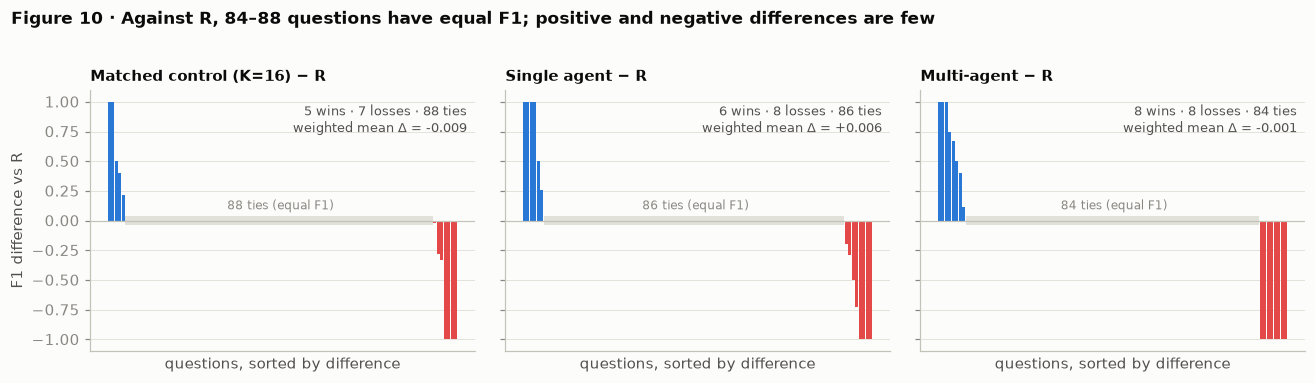

Matched control (K=16)   wins  5  losses  7  ties 88  weighted mean ΔF1 -0.009
Single agent             wins  6  losses  8  ties 86  weighted mean ΔF1 +0.006
Multi-agent              wins  8  losses  8  ties 84  weighted mean ΔF1 -0.001
stored intervals: single − R +0.006 [-0.075, +0.090] (confirmatory, no clear difference demonstrated); multi − R -0.001 [-0.092, +0.092] (secondary)


In [12]:
W = final.question_weights(TYPES)
QL = list(Q)
STORED = {"agent_single": CONF["F2"]["delta"],
          "multi_agent": A["test_agents"]["secondary_comparisons"]["multi_minus_R"]["f1"]["delta"]}
PAIRED = {}
for n in ("d3_k16", "agent_single", "multi_agent"):
    d = np.array([SC[n][q]["f1"] - SC["d3_k10"][q]["f1"] for q in QL])
    mean = float(np.average(d, weights=[W[q] for q in QL]))
    if n in STORED:
        assert abs(mean - STORED[n]) < 1e-9, (n, mean, STORED[n])
    PAIRED[n] = {"d": d, "win": int((d > 0).sum()), "loss": int((d < 0).sum()), "tie": int((d == 0).sum()), "mean": mean}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
fig.subplots_adjust(left=0.07, right=0.99, top=0.78, bottom=0.12, wspace=0.08)
for ax, (n, p) in zip(axes, PAIRED.items()):
    d = np.sort(p["d"])[::-1]
    ax.bar(range(len(d)), d, width=0.8, color=[WIN if x > 0 else LOSS if x < 0 else TIE for x in d], linewidth=0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.add_patch(plt.Rectangle((p["win"] - 0.4, -0.04), p["tie"] - 0.2, 0.08, color=TIE, lw=0))
    ax.text(p["win"] + p["tie"] / 2, 0.07, f"{p['tie']} ties (equal F1)", ha="center", va="bottom", fontsize=8, color=MUTED)
    ax.set_xticks([])
    ax.set_xlabel("questions, sorted by difference")
    ax.set_title(f"{NAME[n]} − R", loc="left", fontsize=10)
    ax.text(0.98, 0.95, f"{p['win']} wins · {p['loss']} losses · {p['tie']} ties\nweighted mean Δ = {p['mean']:+.3f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)
axes[0].set_ylabel("F1 difference vs R")
fig.suptitle(f"Figure 10 · Against R, {min(p['tie'] for p in PAIRED.values())}–{max(p['tie'] for p in PAIRED.values())} questions have equal F1; "
             "positive and negative differences are few", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
plt.show()
for n, p in PAIRED.items():
    print(f"{NAME[n]:<24} wins {p['win']:>2}  losses {p['loss']:>2}  ties {p['tie']:>2}  weighted mean ΔF1 {p['mean']:+.3f}")
print(f"stored intervals: single − R {CONF['F2']['delta']:+.3f} [{CONF['F2']['ci_low']:+.3f}, {CONF['F2']['ci_high']:+.3f}] (confirmatory, "
      f"{CONF['F2']['conclusion']}); multi − R "
      + "{delta:+.3f} [{ci_low:+.3f}, {ci_high:+.3f}] (secondary)".format(**A["test_agents"]["secondary_comparisons"]["multi_minus_R"]["f1"]))

### Figure 11 · Multi-agent stage flow

- **Left panel:** each `test_agents` question flows through three stages, from left to
  right:
  1. whether both gold paragraphs were anywhere in the **search pool**;
  2. whether both reached the synthesizer's **final context**;
  3. the **answer outcome**.

  Band width is the raw number of questions, out of the balanced 100. Bands are coloured
  by the answer outcome.
- **Right panel:** the hard role failures recorded in the run (schema or reference errors
  that the graph logged and handled).
  - A question can have several of them, so they overlap with the flow on the left.
  - They are not exclusive causes of any path.

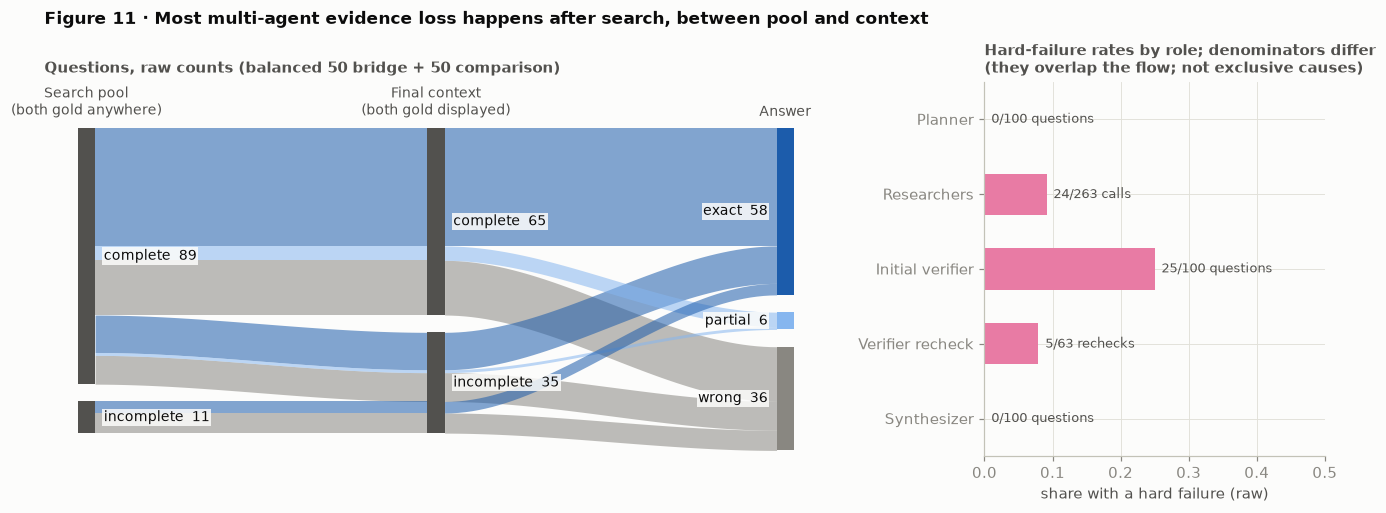

both gold in pool 89/100 -> in final context 65/100 (lost between: 24)
answer outcome by path:
  pool complete   context complete   exact    41
  pool complete   context complete   partial   5
  pool complete   context complete   wrong    19
  pool complete   context incomplete exact    13
  pool complete   context incomplete partial   1
  pool complete   context incomplete wrong    10
  pool incomplete context incomplete exact     4
  pool incomplete context incomplete wrong     7
exact-answer rate, context complete: 41/65 (descriptive; not a causal estimate)
exact-answer rate, lost between pool and context: 13/24 (descriptive; not a causal estimate)
questions with >=1 hard role failure: 48/100; of these, context complete 26, exact 28


In [13]:
MA = REC["multi_agent"]
ANS = ["correct", "partial", "wrong"]
ANS_LABEL = {"correct": "exact", "partial": "partial", "wrong": "wrong"}
ANS_COLOR = {"correct": EXACT, "partial": PARTIAL, "wrong": WRONG[1]}
PATH = {q: (has_both(pool("multi_agent", MA[q]), q), has_both(MA[q]["displayed"], q),
            scoring.answer_outcome(SC["multi_agent"][q]["em"], SC["multi_agent"][q]["f1"])) for q in QL}
for t in ("bridge", "comparison"):  # the flow reproduces the stored funnel
    qs = [q for q in QL if TYPES[q] == t]
    assert sum(PATH[q][0] for q in qs) / len(qs) == AG["multi_agent"]["funnel"]["search_pool"][t]
    assert sum(PATH[q][1] for q in qs) / len(qs) == AG["multi_agent"]["funnel"]["final_context"][t]
BANDS = collections.Counter(PATH.values())
COLS = [[True, False], [True, False], ANS]
GAP, NW = 6, 0.05


def node_spans(c):
    spans, y = {}, 0
    for v in COLS[c]:
        h = sum(k for p, k in BANDS.items() if p[c] == v)
        spans[v] = (y, y + h)
        y += h + GAP
    return spans


SPANS = [node_spans(c) for c in range(3)]
ORDER = {v: i for col in COLS for i, v in enumerate(col)}


def band_offsets(c):  # position of each band inside its node at column c
    off, cursor = {}, {v: s[0] for v, s in SPANS[c].items()}
    for p in sorted(BANDS, key=lambda p: (ORDER[p[c]], [ORDER[x] for x in p[:c] + p[c + 1:]])):
        off[p] = cursor[p[c]]
        cursor[p[c]] += BANDS[p]
    return off


OFFS = [band_offsets(c) for c in range(3)]
fig, (ax, axr) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
fig.subplots_adjust(left=0.01, right=0.98, top=0.84, bottom=0.1, wspace=0.28)
s = np.linspace(0, 1, 50)
ease = s * s * (3 - 2 * s)
for p, k in BANDS.items():
    for c in range(2):
        x = c + NW / 2 + s * (1 - NW)
        y0, y1 = OFFS[c][p], OFFS[c + 1][p]
        top = y0 + (y1 - y0) * ease
        ax.fill_between(x, top, top + k, color=ANS_COLOR[p[2]], alpha=0.55, lw=0)
STAGE = ["Search pool\n(both gold anywhere)", "Final context\n(both gold displayed)", "Answer"]
for c in range(3):
    for v, (a, b) in SPANS[c].items():
        ax.add_patch(plt.Rectangle((c - NW / 2, a), NW, b - a, color=ANS_COLOR[v] if c == 2 else INK2, lw=0))
        lab = ANS_LABEL[v] if c == 2 else ("complete" if v else "incomplete")
        ax.text(c + (NW if c < 2 else -NW), (a + b) / 2, f"{lab}  {b - a}", va="center", ha="left" if c < 2 else "right",
                fontsize=9, color=INK, bbox=dict(fc=SURFACE, ec="none", pad=1, alpha=0.85))
    ax.text(c, -3, STAGE[c], ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xlim(-0.12, 2.12)
ax.set_ylim(max(b for sp in SPANS for _, b in sp.values()) + 2, -16)
ax.axis("off")
ax.set_title("Questions, raw counts (balanced 50 bridge + 50 comparison)", loc="left", fontsize=9.5, color=INK2)
RF = AG["multi_agent"]["role_failures"]
role_rows = [("Planner", RF["planner"], "questions"), ("Researchers", RF["researchers"], "calls"),
             ("Initial verifier", RF["initial verifier"], "questions"), ("Verifier recheck", RF["recheck"], "rechecks")]
syn_k = sum(MA[q]["schema_error"] for q in QL)
role_rows.append(("Synthesizer", {"bridge": {"k": syn_k, "n": 50}, "comparison": {"k": 0, "n": 50}} if syn_k == 0 else None, "questions"))
for i, (lab, d, unit) in enumerate(role_rows):
    k, n = d["bridge"]["k"] + d["comparison"]["k"], d["bridge"]["n"] + d["comparison"]["n"]
    axr.barh(i, k / n, height=0.55, color=COLOR["multi_agent"])
    axr.text(k / n + 0.01, i, f"{k}/{n} {unit}", va="center", fontsize=8.5, color=INK2)
axr.set_yticks(range(len(role_rows)), [r[0] for r in role_rows])
axr.invert_yaxis()
axr.set_xlim(0, 0.5)
axr.set_xlabel("share with a hard failure (raw)")
axr.set_title("Hard-failure rates by role; denominators differ\n(they overlap the flow; not exclusive causes)", loc="left", fontsize=9.5, color=INK2)
fig.suptitle("Figure 11 · Most multi-agent evidence loss happens after search, between pool and context",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.show()
pool_c = sum(p[0] for p in PATH.values()); ctx_c = sum(p[1] for p in PATH.values())
lost = [q for q in QL if PATH[q][0] and not PATH[q][1]]
print(f"both gold in pool {pool_c}/100 -> in final context {ctx_c}/100 (lost between: {len(lost)})")
print("answer outcome by path:")
for p in sorted(BANDS, key=lambda p: [ORDER[x] for x in p]):
    print(f"  pool {'complete' if p[0] else 'incomplete':<10} context {'complete' if p[1] else 'incomplete':<10} {ANS_LABEL[p[2]]:<7} {BANDS[p]:>3}")
for name, cond in (("context complete", lambda q: PATH[q][1]), ("lost between pool and context", lambda q: q in lost)):
    qs = [q for q in QL if cond(q)]
    print(f"exact-answer rate, {name}: {sum(PATH[q][2] == 'correct' for q in qs)}/{len(qs)} (descriptive; not a causal estimate)")
HARD = {"researcher_error", "verifier_error", "recheck_error"}
failed = [q for q in QL if any(e["event"] in HARD for e in MA[q]["events"])]
print(f"questions with >=1 hard role failure: {len(failed)}/100; of these, context complete {sum(PATH[q][1] for q in failed)}, "
      f"exact {sum(PATH[q][2] == 'correct' for q in failed)}")

### Figure 12 · The blinded audit

- **The sample:** 24 outputs per system (12 bridge + 12 comparison), for the four audited
  systems. This deliberately balanced sample is not an estimate of population prevalence.
- **Labelling:** labelled by hand, with system names, scores, the `supported` flag and
  the gold answers hidden.
- **Three separate measurements**, kept in separate panels:
  - **(a)** the human support label;
  - **(b)** the human citation-validity label;
  - **(c)** automatic answer correctness against the gold answer.
- **Panel (d):** the preregistered unsupported-claim rate. Among outputs that the system
  itself marked `supported = true`, it is the share labelled unsupported or contradicted,
  with exact 95% intervals.

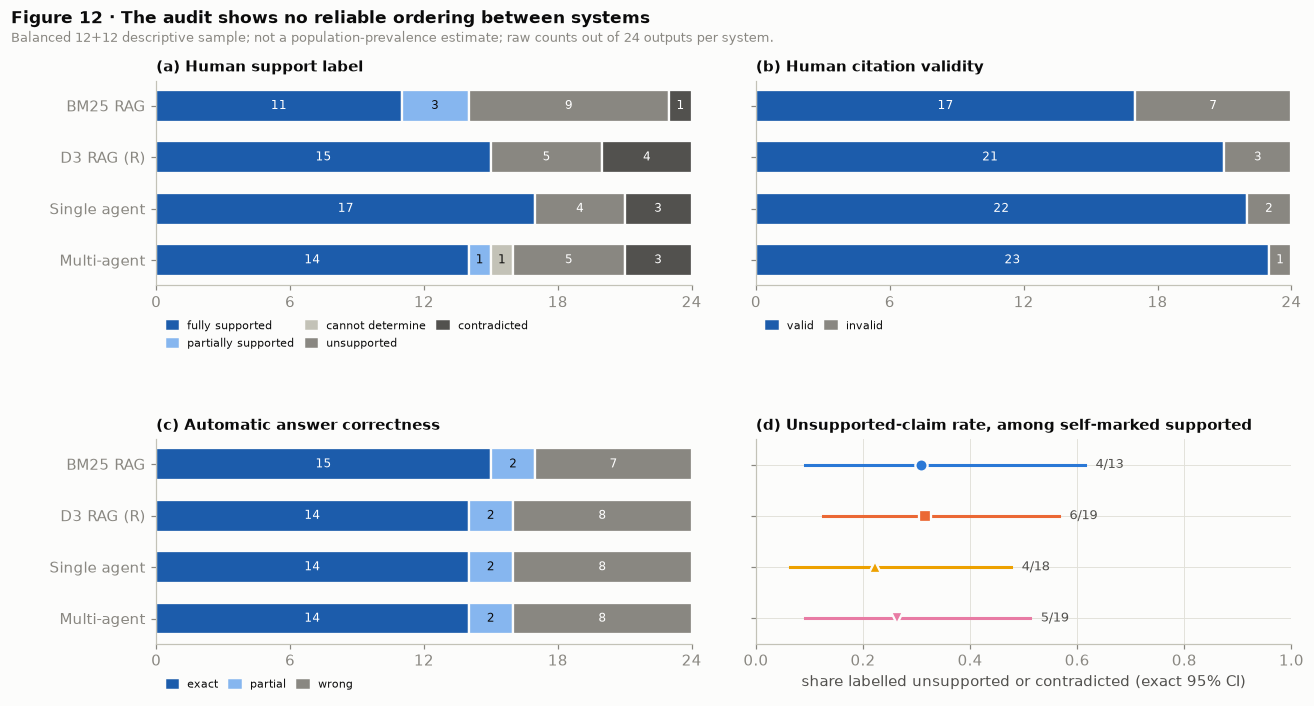

BM25 RAG       fully supported 11/24  valid citations 17/24  exact answers 15/24  unsupported-claim 4/13 = 0.31 [0.09, 0.61]
D3 RAG (R)     fully supported 15/24  valid citations 21/24  exact answers 14/24  unsupported-claim 6/19 = 0.32 [0.13, 0.57]
Single agent   fully supported 17/24  valid citations 22/24  exact answers 14/24  unsupported-claim 4/18 = 0.22 [0.06, 0.48]
Multi-agent    fully supported 14/24  valid citations 23/24  exact answers 14/24  unsupported-claim 5/19 = 0.26 [0.09, 0.51]


In [14]:
AUD_SYS = list(final.AUDIT_SYSTEMS)  # AKEY and ALAB were validated in Part 0
AUD_ANS = {s: collections.Counter(scoring.answer_outcome(SC[s][k["qid"]]["em"], SC[s][k["qid"]]["f1"])
                                  for k in AKEY if k["system"] == s) for s in AUD_SYS}
for s in AUD_SYS:  # the joined labels reproduce the stored audit analysis
    rows = [ALAB[k["item"]] for k in AKEY if k["system"] == s]
    assert collections.Counter(r["support"] for r in rows) == {k: v for k, v in AUDIT[s]["balanced_audit"]["support_distribution"].items() if v}
    assert sum(AUD_ANS[s].values()) == AUDIT[s]["balanced_audit"]["n_outputs"] == 24
SUPPORT = [("fully_supported", "fully supported", EXACT), ("partially_supported", "partially supported", PARTIAL),
           ("cannot_determine", "cannot determine", WRONG[2]), ("unsupported", "unsupported", WRONG[1]),
           ("contradicted", "contradicted", WRONG[0])]
CITE = [("valid", "valid", EXACT), ("invalid", "invalid", WRONG[1])]
ANSW = [("correct", "exact", EXACT), ("partial", "partial", PARTIAL), ("wrong", "wrong", WRONG[1])]
PANELS = [("(a) Human support label", SUPPORT, lambda s: AUDIT[s]["balanced_audit"]["support_distribution"]),
          ("(b) Human citation validity", CITE, lambda s: AUDIT[s]["balanced_audit"]["citation_distribution"]),
          ("(c) Automatic answer correctness", ANSW, lambda s: AUD_ANS[s])]
fig, axs = plt.subplots(2, 2, figsize=(12, 6.4))
fig.subplots_adjust(left=0.12, right=0.98, top=0.88, bottom=0.08, hspace=0.75, wspace=0.12)
for ax, (title, cats, get) in zip(axs.flat, PANELS):
    for i, s in enumerate(AUD_SYS):
        left = 0
        for key, _, col in cats:
            v = get(s).get(key, 0)
            if v:
                ax.barh(i, v, left=left, height=0.62, color=col, edgecolor=SURFACE, linewidth=1.5)
                ax.text(left + v / 2, i, str(v), ha="center", va="center", fontsize=8,
                        color="white" if col in (EXACT, WRONG[0], WRONG[1]) else INK)
            left += v
    ax.set_yticks(range(len(AUD_SYS)), [NAME[s] for s in AUD_SYS])
    ax.invert_yaxis()
    ax.set_xlim(0, 24)
    ax.set_xticks([0, 6, 12, 18, 24])
    ax.grid(False)
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=l) for _, l, c in cats], loc="upper left",
              bbox_to_anchor=(0, -0.12), ncol=3, fontsize=7.5, frameon=False, handlelength=1, columnspacing=1)
axs[0, 1].set_yticklabels([])
ax = axs[1, 1]
for i, s in enumerate(AUD_SYS):
    u = AUDIT[s]["balanced_audit"]["unsupported_claim_rate"]
    ax.plot(u["ci95"], [i, i], color=COLOR[s], lw=2)
    ax.plot(u["rate"], i, MARKER[s], color=COLOR[s], ms=8, mec=SURFACE, mew=1.5)
    ax.text(u["ci95"][1] + 0.02, i, f"{u['k']}/{u['n']}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(AUD_SYS)), [])
ax.set_ylim(len(AUD_SYS) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.set_xlabel("share labelled unsupported or contradicted (exact 95% CI)")
ax.set_title("(d) Unsupported-claim rate, among self-marked supported", loc="left", fontsize=10)
fig.suptitle("Figure 12 · The audit shows no reliable ordering between systems", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.text(0.01, 0.935, AUDIT["bm25_k10"]["balanced_audit"]["note"].capitalize() + "; raw counts out of 24 outputs per system.",
         fontsize=8.5, color=MUTED)
plt.show()
for s in AUD_SYS:
    b = AUDIT[s]["balanced_audit"]; u = b["unsupported_claim_rate"]
    print(f"{NAME[s]:<14} fully supported {b['support_distribution']['fully_supported']:>2}/24  valid citations "
          f"{b['citation_distribution']['valid']:>2}/24  exact answers {AUD_ANS[s]['correct']:>2}/24  "
          f"unsupported-claim {u['k']}/{u['n']} = {u['rate']:.2f} [{u['ci95'][0]:.2f}, {u['ci95'][1]:.2f}]")

### The five case studies, linked to the figures

The case studies in [`reports/case_studies.md`](reports/case_studies.md) are post hoc
qualitative examples, chosen after the results were inspected. They do not provide a
representative example of every taxonomy class.

The table below links each case to the figure where its mechanism shows up at scale. For
the four blind-test cases, it looks up each compared system's taxonomy class from Figure 8
(the case manifest is `demo_cases.toml`; `python demo.py --case <id>` replays one offline).

In [15]:
import demo
from IPython.display import Markdown, display
AT_SCALE = {"graph_success": "Fig. 5 (bridge retrieval), Fig. 8", "rerank_failure": "none here: `tune`, retrieval only",
            "agent_recovery": "Fig. 6, Fig. 10 (single-agent wins)", "unnecessary_search": "Fig. 10 (single-agent losses)",
            "selection_loss": "Fig. 11 (pool → context)"}
rows = ["| # | Case | Split | Systems compared: taxonomy class | Mechanism at scale |", "|---|---|---|---|---|"]
for c in demo.load_cases():
    if c["split"] == "test_agents":
        cls = "; ".join(f"{NAME[n]}: {TAX[n][c['qid']]}" for n in c["systems"])
    else:
        cls = ", ".join(c["systems"]) + " (no answers generated)"
    rows.append(f"| {c['number']} | {c['title'].split(':')[0]} | `{c['split']}` | {cls} | {AT_SCALE[c['id']]} |")
display(Markdown("\n".join(rows)))

| # | Case | Split | Systems compared: taxonomy class | Mechanism at scale |
|---|---|---|---|---|
| 1 | Graph success | `test_agents` | BM25 RAG: wrong · incomplete final context; D3 RAG (R): exact | Fig. 5 (bridge retrieval), Fig. 8 |
| 2 | Reranking failure | `tune` | D3, X1 (no answers generated) | none here: `tune`, retrieval only |
| 3 | Useful agent recovery | `test_agents` | D3 RAG (R): wrong · incomplete final context; Single agent: exact | Fig. 6, Fig. 10 (single-agent wins) |
| 4 | Unnecessary search | `test_agents` | D3 RAG (R): exact; Single agent: wrong · complete gold context | Fig. 10 (single-agent losses) |
| 5 | Multi-agent selection loss | `test_agents` | D3 RAG (R): exact; Multi-agent: wrong · incomplete final context | Fig. 11 (pool → context) |

## Part C · Takeaways

Each takeaway below is printed from the data objects behind the figures above. None of
the numbers is typed by hand.

- **Confirmatory and secondary statements** quote the stored preregistered analysis.
- **Everything from Part B is descriptive.**

In [16]:
def ci(d, key="delta"):
    return f"{d[key]:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]"


lines = []
concl = {CONF[k]["conclusion"] for k in CONF}
lines.append("1. Preregistered comparisons on the frozen blind test (answer F1, test_agents, prevalence-weighted):")
for k in sorted(CONF):
    c = CONF[k]
    lines.append(f"   {k} {NAME[c['a']]} − {NAME[c['b']]}: {ci(c)}, Holm p = {c['p_holm']:.3f} → {c['conclusion']}")
if concl == {"no clear difference demonstrated"}:
    lines.append("   None of the three demonstrated a difference; this is not evidence of equivalence (Figure 1).")
jr = RET["jr10_d3_minus_bm25"]; rf = A["test_rag"]["R_minus_baseline"]["f1"]
lines.append(f"2. Secondary comparisons whose 95% interval excludes zero: Joint Recall@10, D3 − BM25 = {ci(jr)} "
             f"on test_retrieval (n = {jr['n']}); answer F1, R − BM25 = {ci(rf)} on test_rag (n = {rf['n']}) (retrieval curves: Figure 5).")
lines.append("3. Wrong bridge answers by final context (raw counts; final contexts differ in size, Figure 8):")
for n in TAX_SYS:
    c = COUNTS["bridge"][n]
    lines.append(f"   {NAME[n]:<24} {c[CLASSES[2]] + c[CLASSES[3]]} wrong: {c[CLASSES[2]]} with incomplete final context, "
                 f"{c[CLASSES[3]]} despite complete gold context")
lines.append("   Wrong answers despite complete gold context are not explained by missing evidence.")
lines.append("4. Paired against R (Figure 10): " + "; ".join(
    f"{NAME[n]} {p['win']} wins / {p['loss']} losses / {p['tie']} ties (weighted mean Δ {p['mean']:+.3f})" for n, p in PAIRED.items()) + ".")
fn = AG["multi_agent"]["funnel"]
lines.append(f"5. Multi-agent selection (Figure 11): both gold paragraphs in the search pool for {pool_c}/100 questions, in the final "
             f"context for {ctx_c}/100 (weighted {fn['search_pool']['overall']:.3f} → {fn['final_context']['overall']:.3f}). "
             "Whether this loss lowered answer F1 is not established.")
p50 = {n: SYS_A[n]["cost"]["llm_seconds"]["p50"] for n in ("d3_k10", "agent_single", "multi_agent")}
lines.append(f"6. Cost (Figure 7): median attributed LLM wall-time R {p50['d3_k10']:.1f} s, single agent {p50['agent_single']:.1f} s "
             f"({p50['agent_single'] / p50['d3_k10']:.1f}×), multi-agent {p50['multi_agent']:.1f} s "
             f"({p50['multi_agent'] / p50['d3_k10']:.1f}×), with no demonstrated F1 gain.")
fs = sorted(AUD_SYS, key=lambda s: -AUDIT[s]["balanced_audit"]["support_distribution"]["fully_supported"])
lines.append("7. Audit (Figure 12, balanced 12 + 12 sample): fully supported " + ", ".join(
    f"{NAME[s]} {AUDIT[s]['balanced_audit']['support_distribution']['fully_supported']}/24" for s in fs)
    + "; in a sample this small this is not a reliable ordering.")
lines.append(f"8. Shared difficulty (Figure 9): all five compared systems were wrong on {len(all_wrong)} questions, and the oracle "
             f"was also wrong on {sum(outcome['oracle'][q] == 'wrong' for q in all_wrong)} of them: candidates for hard "
             "questions or label problems, not proof of either.")
print("\n".join(lines))

1. Preregistered comparisons on the frozen blind test (answer F1, test_agents, prevalence-weighted):
   F1 D3 RAG (R) − BM25 RAG: +0.070 [-0.041, +0.181], Holm p = 0.663 → no clear difference demonstrated
   F2 Single agent − D3 RAG (R): +0.006 [-0.075, +0.090], Holm p = 1.000 → no clear difference demonstrated
   F3 Multi-agent − Single agent: -0.007 [-0.113, +0.096], Holm p = 1.000 → no clear difference demonstrated
   None of the three demonstrated a difference; this is not evidence of equivalence (Figure 1).
2. Secondary comparisons whose 95% interval excludes zero: Joint Recall@10, D3 − BM25 = +0.237 [+0.207, +0.268] on test_retrieval (n = 1000); answer F1, R − BM25 = +0.077 [+0.008, +0.144] on test_rag (n = 200) (retrieval curves: Figure 5).
3. Wrong bridge answers by final context (raw counts; final contexts differ in size, Figure 8):
   BM25 RAG                 26 wrong: 18 with incomplete final context, 8 despite complete gold context
   D3 RAG (R)               21 wrong: 9 wi